# <a id='toc1_'></a>[Ondas de corpo](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Ondas de corpo](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Uma vez que temos o cálculo das ondas superficiais, podemos também realizar algo análogo para obter os tempos de chegada estimados para as ondas de corpo. Para isso, iremos utilizar a biblioteca `obspy`.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Primeiro, vamos montar uma função que calcula a lista dos tempos de chegada de ondas corpóreas do terremoto

In [2]:
from obspy import taup
import obspy.geodetics as geo

SIRIUS_LOCATION = (-22.807606, -47.052526)
POS_LAT_SIRIUS, POS_LON_SIRIUS = SIRIUS_LOCATION

def arrival_list(
    latitude: float,
    longitude: float,
    depth: float,
    POS_LAT_SIRIUS=POS_LAT_SIRIUS,
    POS_LON_SIRIUS=POS_LON_SIRIUS,
):
    """
    Function that calculates the list of arrival of an earthquake

    Input:

    - latitude: the latitude of the event in degree

    - longitude: the longitude of the event in degree

    - depth: the estimated depth of the event in kilometers

    Output:

    - travel_times: the list of arrivals of each wave that reaches the target

    - epicenter_distance_degree: the epicenter distance between the origin of the event and the target in degree

    - model: the model used to calculate the travel_time

    - model_name: the name of the model used for register purposes
    """

    # geodesic_distance is in meters, azimuth_degree, back_azimuth_degree and epicenter_distance is in degree
    geodesic_distance, azimuth_degree, back_azimuth_degree = geo.gps2dist_azimuth(
        latitude, longitude, POS_LAT_SIRIUS, POS_LON_SIRIUS
    )
    epicenter_distance_degree = geo.locations2degrees(
        latitude, longitude, POS_LAT_SIRIUS, POS_LON_SIRIUS
    )

    model_name = "iasp91"
    model = taup.TauPyModel(model=model_name)

    travel_times = model.get_travel_times(
        source_depth_in_km=depth, distance_in_degree=epicenter_distance_degree
    )

    return travel_times, epicenter_distance_degree, model, model_name


Vamos testar com o mesmo terremoto de antes.

In [6]:
travel_times, epicenter_distance_degree, model, model_name = arrival_list(
    7.19,
    -81.32,
    10,
)

print(f"""
{travel_times=} \n
{epicenter_distance_degree=} \n
{model=} \n
{model_name=} \n      
""")


travel_times=[<obspy.taup.helper_classes.Arrival object at 0x000001D8B5890E90>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5892990>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891790>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891910>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891C10>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5892210>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891F10>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5893110>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891610>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891490>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5893950>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B58931D0>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5891B50>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B5892150>, <obspy.taup.helper_classes.Arrival object at 0x000001D8B58918

Para visualizar podemos usar essa função:

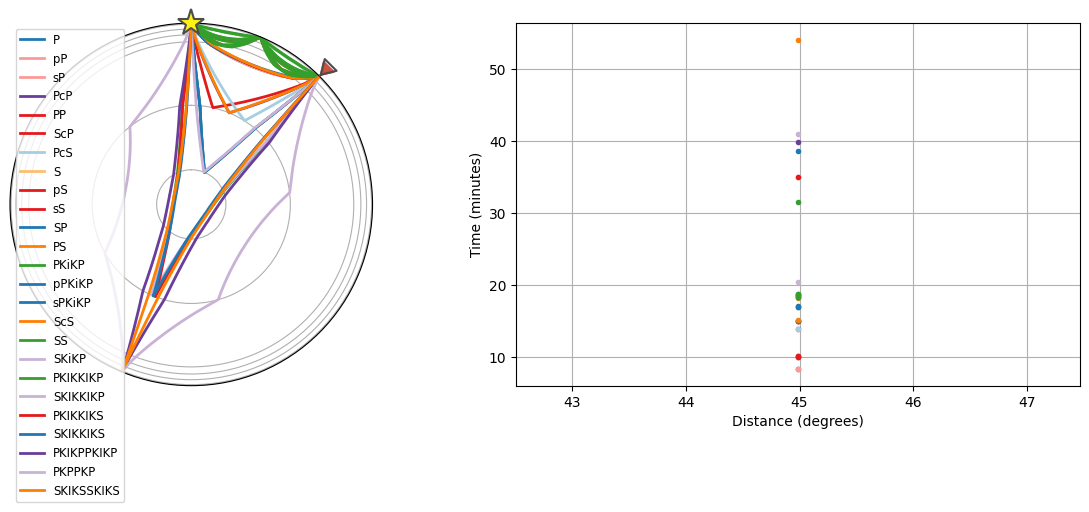

In [8]:
import matplotlib.pyplot as plt

def earth_plot(model: taup.TauPyModel, depth: float, epicenter_distance_degree: float):
    """
    A plot-function, it takes the epicenter distance, the depth and the model


    """

    paths = model.get_ray_paths(depth, epicenter_distance_degree)

    fig = plt.figure(figsize=(12, 5))

    ax_rays = fig.add_subplot(1, 2, 1, projection="polar")
    ax_times = fig.add_subplot(1, 2, 2)

    paths.plot_rays(legend=True, fig=fig, ax=ax_rays, show=False)
    paths.plot_times(legend=False, fig=fig, ax=ax_times, show=False)

    plt.tight_layout()
    plt.show()
    
earth_plot(model, 10, epicenter_distance_degree)

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Agora, conseguimos estimar os tempos de chegada não só das ondas superficiais, mas também das ondas de corpo. O próximo passo será conseguir os terremotos de uma forma automatizada.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. OBSPY. *obspy.geodetics — Geodetic calculations*. [S. l.]: ObsPy Documentation, [s. d.]. Disponível em: https://docs.obspy.org/packages/obspy.geodetics.html.